# 02. EDA + 피처 엔지니어링

`01_data_collection.ipynb`에서 저장한 `data/processed/apt_trade_raw.parquet`를 불러와 탐색적 데이터 분석을 하고, 회귀·군집·분류 노트북에서 공통으로 쓸 피처를 만들어 `data/processed/df_fe.parquet`로 저장합니다.

**현재 수집 범위**: 서울 전체 (전국으로 수집했다가 표본 수 확인 후 서울로 좁힘 — 아래 4번 섹션 참고)

In [77]:
import warnings
warnings.filterwarnings("ignore")

import os
import time
from pathlib import Path

import numpy as np
import pandas as pd
import requests
from dotenv import load_dotenv
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

load_dotenv()

DATA_DIR = Path("../data")
PROCESSED_DIR = DATA_DIR / "processed"
EXTERNAL_DIR = DATA_DIR / "external"

raw_df = pd.read_parquet(PROCESSED_DIR / "apt_trade_raw.parquet")
sigungu_df = pd.read_csv(PROCESSED_DIR / "sigungu_map.csv", encoding="utf-8-sig")

print(raw_df.shape)
raw_df.head()


(474066, 64)


,법정동시군구코드,법정동읍면동코드,법정동지번코드,법정동본번코드,법정동부번코드,도로명,도로명시군구코드,도로명코드,도로명일련번호코드,도로명지상지하코드,...,aptSeq,cdealType,cdealDay,dealingGbn,estateAgentSggNm,rgstDate,aptDong,slerGbn,buyerGbn,landLeaseholdGbn
0,11110.0,17500.0,1.0,766.0,0.0,숭인동길,11110.0,4100204.0,1.0,0.0,...,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
1,11110.0,17400.0,1.0,703.0,0.0,낙산길,11110.0,4100020.0,2.0,0.0,...,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
2,11110.0,11500.0,1.0,9.0,0.0,사직로8길,11110.0,4100135.0,3.0,0.0,...,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
3,11110.0,18000.0,1.0,126.0,0.0,송월길,11110.0,4100192.0,1.0,NaN,...,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan
4,11110.0,11500.0,1.0,9.0,0.0,사직로8길,11110.0,4100135.0,3.0,0.0,...,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan


## 1. 탐색적 데이터 분석 (EDA)

> 실제 API 컬럼명은 데이터셋 버전에 따라 다를 수 있습니다. "상세 자료"(15126468) 기준으로는 `계약년도`, `계약월`, `계약일`, `법정동시군구코드`, `거래금액`, `전용면적`, `건축년도`, `층` 등이 있습니다.

In [78]:
print(raw_df.dtypes)
print("\n결측치 비율:")
print(raw_df.isna().mean().sort_values(ascending=False))


법정동시군구코드            float64
법정동읍면동코드            float64
법정동지번코드             float64
법정동본번코드             float64
법정동부번코드             float64
                     ...   
rgstDate             object
aptDong              object
slerGbn              object
buyerGbn             object
landLeaseholdGbn     object
Length: 64, dtype: object

결측치 비율:
도로명지상지하코드           0.092048
도로명건물본번호코드          0.001671
도로명건물부번호코드          0.001671
도로명코드               0.001504
도로명일련번호코드           0.001487
                      ...   
rgstDate            0.000000
aptDong             0.000000
slerGbn             0.000000
buyerGbn            0.000000
landLeaseholdGbn    0.000000
Length: 64, dtype: float64


In [79]:
raw_df["거래금액"].describe()


count    4.740660e+05
mean     5.397211e+04
std      5.395654e+04
min      8.000000e+02
25%      2.200000e+04
50%      4.000000e+04
75%      6.750000e+04
max      2.500000e+06
Name: 거래금액, dtype: float64

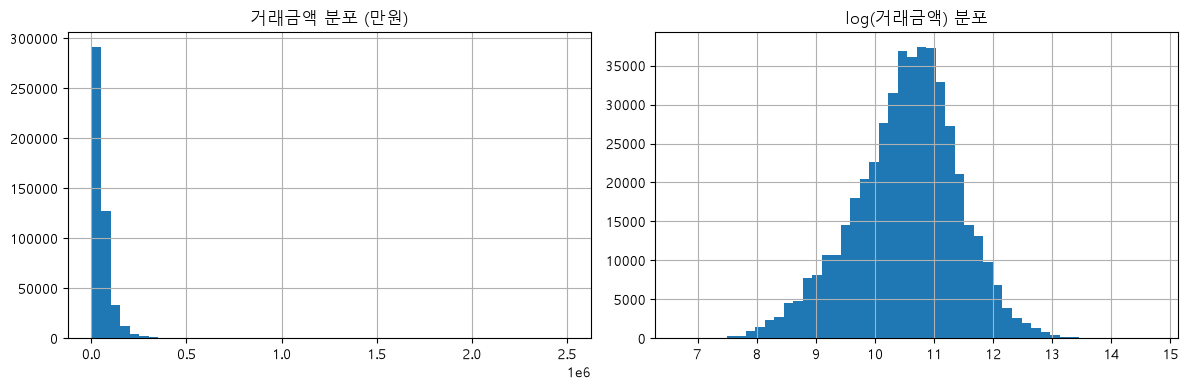

In [80]:
price_col = "거래금액"
df_eda = raw_df.copy()
df_eda[price_col] = (
    df_eda[price_col].astype(str).str.replace(",", "").str.strip().astype(float)
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df_eda[price_col].hist(bins=50, ax=axes[0])
axes[0].set_title("거래금액 분포 (만원)")

np.log1p(df_eda[price_col]).hist(bins=50, ax=axes[1])
axes[1].set_title("log(거래금액) 분포")
plt.tight_layout()
plt.show()


거래금액은 **만원 단위**가 맞습니다 (예: `17,500` → 1억 7,500만원). 분포가 오른쪽으로 긴 꼬리를 가지는 전형적인 부동산 가격 분포라, 로그변환 후 정규분포에 가깝게 바뀌는 걸 오른쪽 그래프에서 확인할 수 있습니다. 이후 회귀 모델의 타겟은 `log1p(거래금액)`로 사용합니다.

## 2. 기본 피처 엔지니어링

- `연식` = 계약년도 - 건축년도
- `거래연월` = 계약년도*100 + 계약월 (시계열 정렬/트렌드 피처)
- `층_구분` = 저층/중층/고층 그룹화
- `평당가` = 거래금액 / 전용면적 (군집 분석에서 활용)
- `법정동시군구코드` → 사람이 읽기 좋은 `시군구명` 매핑 (**`법정동시군구코드`가 `"11110.0"`처럼 소수점 붙은 문자열로 들어올 수 있어 `.0` 제거 후 매핑** — 결측치가 섞인 컬럼을 concat하면 pandas가 float으로 승격시키는 경우가 있어서 발생)
- 타겟 `log_price` = `log1p(거래금액)`

> **`지역평균가`(지역 평균가 기반 타겟인코딩)는 여기서 만들지 않습니다.** 전체 데이터로 계산하면 회귀 모델의 test 정보가 train 피처 계산에 섞이는 데이터 누수가 생기기 때문입니다.
> - 회귀(`03`)에서는 **train 데이터만으로** 계산해서 누수를 막습니다.
> - 군집(`04`)은 train/test 분리가 없는 비지도학습이라 누수 개념이 적용되지 않으므로, 그 노트북에서 전체 데이터 기준으로 자유롭게 계산합니다.

In [81]:
df_fe = df_eda.copy()

df_fe["연식"] = df_fe["계약년도"] - df_fe["건축년도"]
df_fe["거래연월"] = df_fe["계약년도"] * 100 + df_fe["계약월"]

def floor_group(f):
    if f <= 5:
        return "저층"
    elif f <= 15:
        return "중층"
    return "고층"

df_fe["층_구분"] = df_fe["층"].apply(floor_group)

df_fe["log_price"] = np.log1p(df_fe[price_col])
df_fe["평당가"] = df_fe[price_col] / df_fe["전용면적"]

# 법정동시군구코드 정리 ("11110.0" 같은 소수점 문자열 방지) 후 시군구명 매핑
df_fe["법정동시군구코드"] = df_fe["법정동시군구코드"].astype(str).str.replace(r"\.0$", "", regex=True)

region_map = sigungu_df[["시군구코드", "시군구명"]].drop_duplicates()
region_map["시군구코드"] = region_map["시군구코드"].astype(str)
df_fe = df_fe.merge(region_map, left_on="법정동시군구코드", right_on="시군구코드", how="left")

print(df_fe.shape)
print("시군구명 결측치:", df_fe["시군구명"].isna().sum())
df_fe[["법정동시군구코드", "시군구명", "연식", "거래연월", "층_구분", "평당가", "log_price"]].head()


(474066, 71)
시군구명 결측치: 0


,법정동시군구코드,시군구명,연식,거래연월,층_구분,평당가,log_price
0,11110,종로구,16.0,202509.0,저층,1409.681929,11.344519
1,11110,종로구,32.0,202509.0,저층,718.428114,11.326608
2,11110,종로구,17.0,202509.0,저층,1274.479329,12.230770
3,11110,종로구,8.0,202509.0,저층,1744.334268,11.082158
4,11110,종로구,17.0,202509.0,저층,1429.349306,12.254868


In [82]:
# 5년 이내 신축 비율 참고 확인
print(df_fe["연식"].describe())
print("5년 이내 신축 비율:", round((df_fe["연식"] <= 5).mean(), 3))


count    474066.000000
mean         19.500344
std          11.265578
min          -1.000000
25%           9.000000
50%          20.000000
75%          29.000000
max          65.000000
Name: 연식, dtype: float64
5년 이내 신축 비율: 0.129


서울 원도심권(종로·중구·용산·성동·광진 등)은 신규 공급이 적어 최근 거래 대다수가 노후 아파트인 게 정상입니다. 신축 비율이 낮게 나오는 건 데이터 오류가 아니라 시장 특성입니다.

## 3. 수집 범위를 서울로 한정

전국(267개 시군구) 데이터를 수집했지만, 이 프로젝트는 서울 아파트 시장에 집중하기로 해서 여기서 서울만 남깁니다. 아래 지오코딩·거리 계산은 이 필터링 이후 데이터로 진행합니다 (계산량을 줄이기 위해 여기서 먼저 좁힙니다).

In [83]:
df_fe = df_fe[
    df_fe["시군구명"].isin(sigungu_df[sigungu_df["시도명"] == "서울특별시"]["시군구명"])
].reset_index(drop=True)

print(df_fe.shape)


(81541, 71)


## 4. 아파트 좌표 지오코딩 (카카오 API)

같은 단지는 여러 번 거래되므로, **시군구명+법정동+지번+단지명 조합의 고유값 기준으로 캐싱**해서 API 호출을 최소화합니다.

> 주소에 `시군구명`을 포함하는 이유: `법정동`만으로는 동명이 다른 지역에 겹칠 수 있어(예: "신당동"이 여러 지역에 존재) 지오코딩이 엉뚱한 곳으로 될 위험이 있습니다.
> 실제 카카오 검색어(`검색주소`)는 시군구명+법정동+지번까지만 사용합니다 (단지명까지 넣으면 오히려 실패율이 올라감).

In [84]:
KAKAO_API_KEY = os.environ.get("KAKAO_REST_API_KEY", "")

def geocode_address(query: str):
    url = "https://dapi.kakao.com/v2/local/search/address.json"
    headers = {"Authorization": f"KakaoAK {KAKAO_API_KEY}"}
    params = {"query": query}
    try:
        resp = requests.get(url, headers=headers, params=params, timeout=5)
        resp.raise_for_status()
        docs = resp.json().get("documents", [])
        if not docs:
            return None, None
        return float(docs[0]["y"]), float(docs[0]["x"])  # 위도, 경도
    except Exception:
        return None, None

# 테스트
lat, lon = geocode_address("서울특별시 종로구 숭인동")
print(lat, lon)


37.5745280159936 127.019597569646


In [85]:
df_fe["주소"] = df_fe["시군구명"] + " " + df_fe["법정동"] + " " + df_fe["지번"].astype(str) + " " + df_fe["단지명"]      # 캐싱/구분용
df_fe["검색주소"] = df_fe["시군구명"] + " " + df_fe["법정동"] + " " + df_fe["지번"].astype(str)                          # 지오코딩 검색용

addr_to_search = df_fe.drop_duplicates("주소").set_index("주소")["검색주소"]

unique_addresses = df_fe["주소"].dropna().unique()
print(f"고유 주소 수: {len(unique_addresses)} / 전체 거래 건수: {len(df_fe)}")


고유 주소 수: 6500 / 전체 거래 건수: 81541


In [86]:
GEOCODE_CACHE_PATH = EXTERNAL_DIR / "geocode_cache.csv"

if GEOCODE_CACHE_PATH.exists():
    geo_cache = pd.read_csv(GEOCODE_CACHE_PATH, encoding="utf-8-sig")
else:
    geo_cache = pd.DataFrame(columns=["주소", "위도", "경도"])

done_addresses = set(geo_cache["주소"])
todo = [a for a in unique_addresses if a not in done_addresses]
print(f"이미 처리됨: {len(done_addresses)}, 남음: {len(todo)}")

results = []
for i, addr in enumerate(todo, 1):
    query = addr_to_search[addr]
    lat, lon = geocode_address(query)
    results.append({"주소": addr, "위도": lat, "경도": lon})
    time.sleep(0.05)
    if i % 50 == 0 or i == len(todo):
        print(f"진행: {i}/{len(todo)}")
        pd.concat([geo_cache, pd.DataFrame(results)], ignore_index=True).to_csv(
            GEOCODE_CACHE_PATH, index=False, encoding="utf-8-sig"
        )

if results:
    geo_cache = pd.concat([geo_cache, pd.DataFrame(results)], ignore_index=True).drop_duplicates("주소")
    geo_cache.to_csv(GEOCODE_CACHE_PATH, index=False, encoding="utf-8-sig")

success_rate = geo_cache["위도"].notna().mean()
print(f"지오코딩 성공률: {success_rate:.1%}")
geo_cache.head()


이미 처리됨: 29573, 남음: 0
지오코딩 성공률: 99.7%


,주소,위도,경도
0,종로구 숭인동 766 종로청계힐스테이트,37.576030,127.021151
1,종로구 창신동 703 창신쌍용2,37.580323,127.011785
2,종로구 사직동 9 광화문스페이스본(101동~105동),37.574417,126.968881
3,종로구 교북동 126 경희궁자이(4단지),37.571579,126.961393
4,종로구 명륜2가 4 아남1,37.585542,126.999414


In [87]:
geo_cache_clean = geo_cache.dropna(subset=["위도", "경도"])

df_fe = df_fe.merge(geo_cache_clean, on="주소", how="left")
print(f"좌표 매핑 성공: {df_fe['위도'].notna().sum()} / {len(df_fe)}")


좌표 매핑 성공: 81220 / 81541


## 5. 최근접 지하철역 거리

`scipy.spatial.cKDTree`로 모든 역과의 거리를 일일이 계산하지 않고, 최근접 후보를 빠르게 찾은 뒤 `haversine` 공식으로 실제 m 단위 거리를 계산합니다.

In [88]:
subway_df = pd.read_excel(EXTERNAL_DIR / "subway_stations.xlsx")
print(subway_df.shape)
subway_df[["역사명", "노선명", "역위도", "역경도", "운영기관명"]].head()


(1099, 15)


,역사명,노선명,역위도,역경도,운영기관명
0,신사,신분당선,37.516125,127.019761,경기도 신분당선
1,논현,신분당선,37.511115,127.021366,경기도 신분당선
2,신논현,신분당선,37.504555,127.024531,경기도 신분당선
3,강남,신분당선,37.497385,127.027879,경기도 신분당선
4,양재(서초구청),신분당선,37.484454,127.034099,경기도 신분당선


In [89]:
from scipy.spatial import cKDTree

def haversine_m(lat1, lon1, lat2, lon2):
    R = 6371000.0  # 지구 반지름(m)
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2
    return 2 * R * np.arcsin(np.sqrt(a))

def nearest_facility(apt_lat, apt_lon, facility_lat, facility_lon, facility_name):
    """주어진 시설 좌표들 중 각 아파트의 최근접 시설과 거리(m)를 반환한다."""
    coords = np.column_stack([facility_lat, facility_lon])
    tree = cKDTree(coords)
    apt_coords = np.column_stack([apt_lat, apt_lon])
    _, idx = tree.query(apt_coords, k=1)
    dist = haversine_m(apt_lat, apt_lon, coords[idx, 0], coords[idx, 1])
    name = np.asarray(facility_name)[idx]
    return name, dist

apt_coords_mask = df_fe["위도"].notna()

names, dists = nearest_facility(
    df_fe.loc[apt_coords_mask, "위도"].to_numpy(),
    df_fe.loc[apt_coords_mask, "경도"].to_numpy(),
    subway_df["역위도"].to_numpy(),
    subway_df["역경도"].to_numpy(),
    subway_df["역사명"].to_numpy(),
)
df_fe.loc[apt_coords_mask, "최근접역"] = names
df_fe.loc[apt_coords_mask, "역세권거리_m"] = dists

df_fe["역세권거리_m"].describe()


count    81220.000000
mean       759.665412
std       1005.954783
min         28.939448
25%        328.379033
50%        499.260741
75%        736.427642
max       9328.407785
Name: 역세권거리_m, dtype: float64

In [90]:
df_fe[["법정동", "단지명", "최근접역", "역세권거리_m"]].sort_values("역세권거리_m").tail(5)


,법정동,단지명,최근접역,역세권거리_m
74283,강동동,에코델타호반써밋스마트시티,NaN,NaN
74291,강동동,에코델타호반써밋스마트시티,NaN,NaN
74986,강동동,에코델타스마트시티수자인,NaN,NaN
79301,약사동,삼환크리스탈,NaN,NaN
79785,약사동,삼환크리스탈,NaN,NaN


## 6. 최근접 초등학교 거리

지하철역과 동일한 방식(`nearest_facility` 함수 재사용)으로 계산합니다. "학군"의 정교한 지표(학업성취도 등)까지는 아니지만, 초등학교 배정 거리는 부동산 가격에 실질적 영향을 주는 것으로 알려진 지표라 우선 이걸로 시작합니다.

> 데이터 출처: [전국초중등학교위치표준데이터](https://www.data.go.kr/data/15021148/standard.do) (data.go.kr, ID 15021148). `data/external/school_locations.csv`로 저장해두고 사용합니다.

In [92]:
school_df = pd.read_csv(EXTERNAL_DIR / "school_locations.csv", encoding="utf-8-sig")
print(school_df.shape)
print(school_df.columns.tolist())
print(school_df["학교급구분"].value_counts())


(12011, 18)
['학교ID', '학교명', '학교급구분', '설립일자', '설립형태', '본교분교구분', '운영상태', '소재지지번주소', '소재지도로명주소', '시도교육청코드', '시도교육청명', '교육지원청코드', '교육지원청명', '생성일자', '변경일자', '위도', '경도', '데이터기준일자']
학교급구분
초등학교    6303
중학교     3312
고등학교    2396
Name: count, dtype: int64


In [93]:
school_df["운영상태"].value_counts()

운영상태
운영    12011
Name: count, dtype: int64

In [95]:
# 초등학교
elem_df = school_df[
    (school_df["학교급구분"] == "초등학교") &
    (school_df["운영상태"] == "운영")
].dropna(subset=["위도", "경도"]).copy()

names, dists = nearest_facility(
    df_fe.loc[apt_coords_mask, "위도"].to_numpy(),
    df_fe.loc[apt_coords_mask, "경도"].to_numpy(),
    elem_df["위도"].to_numpy(),
    elem_df["경도"].to_numpy(),
    elem_df["학교명"].to_numpy(),
)
df_fe.loc[apt_coords_mask, "최근접초등학교"] = names
df_fe.loc[apt_coords_mask, "초등학교거리_m"] = dists

# 중학교
middle_df = school_df[
    (school_df["학교급구분"] == "중학교") &
    (school_df["운영상태"] == "운영")
].dropna(subset=["위도", "경도"]).copy()

names, dists = nearest_facility(
    df_fe.loc[apt_coords_mask, "위도"].to_numpy(),
    df_fe.loc[apt_coords_mask, "경도"].to_numpy(),
    middle_df["위도"].to_numpy(),
    middle_df["경도"].to_numpy(),
    middle_df["학교명"].to_numpy(),
)
df_fe.loc[apt_coords_mask, "최근접중학교"] = names
df_fe.loc[apt_coords_mask, "중학교거리_m"] = dists

# 고등학교
high_df = school_df[
    (school_df["학교급구분"] == "고등학교") &
    (school_df["운영상태"] == "운영")
].dropna(subset=["위도", "경도"]).copy()

names, dists = nearest_facility(
    df_fe.loc[apt_coords_mask, "위도"].to_numpy(),
    df_fe.loc[apt_coords_mask, "경도"].to_numpy(),
    high_df["위도"].to_numpy(),
    high_df["경도"].to_numpy(),
    high_df["학교명"].to_numpy(),
)
df_fe.loc[apt_coords_mask, "최근접고등학교"] = names
df_fe.loc[apt_coords_mask, "고등학교거리_m"] = dists

df_fe[["초등학교거리_m", "중학교거리_m", "고등학교거리_m"]].describe()


,초등학교거리_m,중학교거리_m,고등학교거리_m
count,81220.000000,81220.000000,81220.000000
mean,333.968437,473.535143,618.992367
std,162.727817,248.284021,367.136640
min,23.319600,24.066877,27.363768
25%,211.696490,282.785390,353.640487
50%,302.547951,436.305168,546.637702
75%,428.038054,617.489082,797.914941
max,1768.785450,2509.854767,3775.985644


In [100]:
df_fe.loc[mask_check, ["위도", "경도"]]

,위도,경도
69440,NaN,NaN
69442,NaN,NaN
69475,NaN,NaN
69476,NaN,NaN
70376,NaN,NaN
70917,NaN,NaN
71106,NaN,NaN
71123,NaN,NaN
71231,NaN,NaN
71248,NaN,NaN


In [101]:
print(df_fe["위도"].isna().sum(), "/", len(df_fe))
print(f"실패율: {df_fe['위도'].isna().mean():.2%}")

# 실패한 것들의 검색주소 확인
fail_addrs = df_fe.loc[df_fe["위도"].isna(), "검색주소"].unique()
print(len(fail_addrs))
fail_addrs[:20]

321 / 81541
실패율: 0.39%
9


array(['성동구 신당동 845', '광진구 자양동 863', '중랑구 묵동 397', '성북구 청량리동 949',
       '구로구 항동 가-238', '강동구 고덕동 BL-3-1', '강서구 강동동 BL-20', '강서구 강동동 가-',
       '중구 약사동 가-3-1'], dtype=object)

In [108]:
mask_check = df_fe["단지명"].isin(["고덕풍경채어바니티", "강서자이에코델타", "삼환크리스탈"])
df_fe.loc[mask_check, ["시군구명", "법정동", "단지명", "위도", "경도"]].drop_duplicates()

,시군구명,법정동,단지명,위도,경도
69440,강동구,고덕동,고덕풍경채어바니티,NaN,NaN
73730,강서구,강동동,강서자이에코델타,NaN,NaN
79301,중구,약사동,삼환크리스탈,NaN,NaN


In [109]:
print(f"학교/지하철역거리 결측 제외 전: {len(df_fe)}")
print(f"위도(=지오코딩 성공) 결측: {df_fe['위도'].isna().sum()} ({df_fe['위도'].isna().mean():.2%})")

학교/지하철역거리 결측 제외 전: 81541
위도(=지오코딩 성공) 결측: 321 (0.39%)


In [106]:
df_fe[["법정동", "단지명", "최근접초등학교", "초등학교거리_m","중학교거리_m","고등학교거리_m"]].sort_values("초등학교거리_m").tail(5)
df_fe[["법정동", "단지명", "최근접초등학교", "초등학교거리_m","중학교거리_m","고등학교거리_m"]].sort_values("중학교거리_m").head(5)
# df_fe[["법정동", "단지명", "최근접초등학교", "초등학교거리_m","중학교거리_m","고등학교거리_m"]].sort_values("고등학교거리_m").tail(20)



,법정동,단지명,최근접초등학교,초등학교거리_m,중학교거리_m,고등학교거리_m
39867,신정동,뉴목동,서울남명초등학교,102.602319,24.066877,894.502350
9859,장안동,현대리노빌101동,서울안평초등학교,152.037464,29.466940,1294.277588
3911,마장동,왕십리금호어울림,서울마장초등학교,603.413101,35.877315,189.913004
3913,마장동,왕십리금호어울림,서울마장초등학교,603.413101,35.877315,189.913004
3844,마장동,왕십리금호어울림,서울마장초등학교,603.413101,35.877315,189.913004


## 시각화

In [ ]:
# 

## 7. 저장

회귀(`03`) · 군집(`04`) · 분류(`05`) 노트북이 공통으로 이 파일 하나만 로드하면 되도록 저장합니다.

In [ ]:
df_fe.to_parquet(PROCESSED_DIR / "df_fe.parquet", index=False)
print(f"저장 완료: {PROCESSED_DIR / 'df_fe.parquet'} ({df_fe.shape[0]}행, {df_fe.shape[1]}열)")


## 다음 단계

`03_regression.ipynb`에서 `feature_cols`에 `역세권거리_m`, `초등학교거리_m`을 추가해서 재실행하면 됩니다.